# Fase 2 · Obtención, exploración, limpieza y transformación
**Pertenencia al SNSS y nivel de complejidad de los establecimientos de salud en Chile**

**Grupo 1:** Brian Cerda · Kattia Espinoza · Karla Martínez · Christopher Ulloa

Construiremos una población reproducible, describiremos ambas variables y prepararemos una matriz numérica. F3 reorganizará este flujo en un diseño modular orientado a objetos; la prueba de independencia y la medida de magnitud se desarrollarán en F4.

> **Cambio por devolución docente (prioridad 4).** Antes decía: “La prueba de independencia y la medida de magnitud se desarrollarán en F3–F4”.

**Recorrido:** obtener → explorar → delimitar → describir → codificar → validar → guardar.

### Registro de cambios por devolución docente
- **Prioridad 4 · Articulación con las fases.** La introducción, la nota sobre la correlación de Pearson, los metadatos de exportación (`prueba_asociacion`) y la conclusión de continuidad indican ahora que F3 reorganiza el flujo en un diseño modular orientado a objetos y que la prueba de independencia corresponde a F4. Se agregó la advertencia de que el tipo de establecimiento puede explicar parte de la asociación observada.
- El código y los resultados del preprocesamiento no cambiaron: la población (4.603), la matriz 0/1 y la tabla de contingencia son idénticas a la versión anterior.

## Introducción y configuración
Recuperaremos la pregunta y los objetivos guardados en F1. Si falta su configuración, el cuaderno pedirá ejecutar F1. Esto mantiene la continuidad entre las fases.

Se usarán tablas y gráficos para justificar las decisiones. Los resultados descriptivos se interpretarán con sus denominadores; no se atribuirá causalidad ni calidad de atención a una diferencia de complejidad.

Las dos dimensiones del cruce se recuperan desde `PROYECTO`: la **administrativa** (pertenencia al SNSS: SNSS / No SNSS) y la **asistencial** (complejidad: Baja / Mediana / Alta).

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
RAIZ = Path.cwd().parent if Path.cwd().name in {"F1", "F2"} else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.utilidades import cargar_datos, normalizar_texto

ruta_configuracion = RAIZ / "docs/proyecto.json"
if not ruta_configuracion.exists():
    raise FileNotFoundError("Ejecute primero el cuaderno de Fase 1 desde su carpeta o la raíz del proyecto.")
PROYECTO = json.loads(ruta_configuracion.read_text(encoding="utf-8"))
METADATOS_F1 = json.loads((RAIZ / "docs/metadatos_f1.json").read_text(encoding="utf-8"))
DIR_FIGURAS = RAIZ / "docs/figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
COLORES = ["#177E89", "#E6A23C", "#7353A6"]
ADMINISTRATIVA, ASISTENCIAL = PROYECTO["dimensiones"]["principales"]
orden_grupos = ADMINISTRATIVA["categorias"]
orden_complejidad = ASISTENCIAL["categorias"]
for dimension in (ADMINISTRATIVA, ASISTENCIAL):
    print(f"Dimensión {dimension['dimension']}: {dimension['columna']} → {dimension['variable']} ({' / '.join(dimension['categorias'])})")
print(PROYECTO["pregunta"])
print("Objetivos de esta fase:")
for objetivo in PROYECTO["objetivos_especificos"][1:4]:
    print("-", objetivo)

Dimensión Administrativa: TipoPertenenciaEstabGlosa → pertenencia_snss (SNSS / No SNSS)
Dimensión Asistencial: NivelComplejidadEstabGlosa → complejidad (Baja / Mediana / Alta)
¿Existe asociación entre la pertenencia al SNSS y el nivel de complejidad en los establecimientos de salud vigentes con código único y con ambas variables informadas en la base?
Objetivos de esta fase:
- Definir la población de análisis mediante criterios explícitos y reproducibles, documentados en una tabla de filtros (Fase 2).
- Estandarizar las categorías de pertenencia al SNSS y de nivel de complejidad, y validar los datos resultantes (Fase 2).
- Describir la distribución de los establecimientos según su pertenencia al SNSS y su nivel de complejidad (Fase 2).


## 1. Obtención de los datos
Leeremos todas las columnas como texto para preservar identificadores, espacios y categorías originales. Usaremos `keep_default_na=False` para distinguir celdas vacías de etiquetas como `No Aplica`. Después definiremos explícitamente qué significa cada caso.

In [2]:
ARCHIVO = RAIZ / "data/raw" / PROYECTO["fuente"]["archivo"]
datos_originales = cargar_datos(ARCHIVO)
assert hashlib.sha256(ARCHIVO.read_bytes()).hexdigest() == METADATOS_F1["sha256"]
print("Dimensiones:", datos_originales.shape)
display(datos_originales.head(3))

Dimensiones: (5837, 33)


,EstablecimientoCodigoAntiguo,EstablecimientoCodigo,EstablecimientoCodigoMadreAntiguo,EstablecimientoCodigoMadreNuevo,RegionCodigo,RegionGlosa,SeremiSaludCodigo_ServicioDeSaludCodigo,SeremiSaludGlosa_ServicioDeSaludGlosa,TipoPertenenciaEstabGlosa,TipoEstablecimientoGlosa,AmbitoFuncionamiento,EstablecimientoGlosa,Certificacion,DependenciaAdministrativa,NivelAtencionEstabglosa,ComunaCodigo,ComunaGlosa,TipoViaGlosa,NombreVia,Numero,TelefonoMovil_TelefonoFijo,FechaInicioFuncionamientoEstab,TieneServicioUrgencia,TipoUrgencia,ClasificacionTipoSapu,Latitud,Longitud,TipoSistemaSaludGlosa,EstadoFuncionamiento,NivelComplejidadEstabGlosa,TipoAtencionEstabGlosa,FechaIncorporacion,FechaCierre
0,01-011,101011,01-010,101010,15,Arica Parinacota,01,Servicio de Salud Arica y Parinacota,Perteneciente al Sistema Nacional de Servicios de Salud,Otro,Programa de Atención,PRAIS (S.S Arica),No Aplica,Servicio de Salud,No Aplica,15101,Arica,Calle,Arturo Prat,305,,,NO,No Aplica,No Aplica,-18.484664,-70.303464,Público,Vigente en Operación Habitual,Baja Complejidad,Atención Abierta-Ambulatoria,,
1,,200601,01-010,101010,15,Arica Parinacota,01,Servicio de Salud Arica y Parinacota,Perteneciente al Sistema Nacional de Servicios de Salud,Hospital de Día,Establecimiento de Salud,Hospital de Día Adulto Arica,No Aplica,Servicio de Salud,Segundo Nivel,15101,Arica,Calle,"Arturo Gallo, interior Hospital Regional Dr. Juan Noé Crevanni",,2204676,05-08-2012,NO,No Aplica,No Aplica,-18.482428,-70.313964,Público,Vigente en Operación Habitual,Mediana Complejidad,Atención Abierta-Ambulatoria,,
2,,101608,01-010,101010,15,Arica Parinacota,01,Servicio de Salud Arica y Parinacota,Perteneciente al Sistema Nacional de Servicios de Salud,Centro Comunitario de Salud Mental (COSAM),Unidad de Atención,COSAM Sur de Arica,No Aplica,Servicio de Salud,Segundo Nivel,15101,Arica,Calle,Benjamín Vicuña Mackenna,630,582204100,,NO,No Aplica,No Aplica,-18.481647,-70.312143,Público,Vigente en Operación Habitual,Mediana Complejidad,Atención Abierta-Ambulatoria,,


**Resultado e interpretación.** Se cargaron **5.837 filas y 33 columnas**. La huella coincide con F1, de modo que ambas fases trabajan con el mismo archivo. Su nombre no basta para asumir que todas las filas corresponden a establecimientos vigentes: lo verificaremos en el diagnóstico.

## 2. Exploración inicial y reporte descriptivo
Generaremos un perfil sencillo con `pandas`: tipo de almacenamiento, celdas vacías, etiquetas `No Aplica` y cantidad de valores distintos. Esta alternativa permite revisar cada cálculo sin agregar una biblioteca de profiling.

Los tipos aparecerán como texto por la decisión de carga. El significado estadístico de cada variable está en el diccionario de F1. Un porcentaje alto de `No Aplica` no equivale automáticamente a mala calidad ni exige imputación.

In [3]:
def crear_perfil(datos):
    """Resume completitud y diversidad sin modificar el DataFrame."""
    filas = []
    for columna in datos.columns:
        valores = normalizar_texto(datos[columna])
        vacios = valores.isna() | valores.eq("").fillna(False)
        no_aplica = valores.eq("no aplica").fillna(False)
        filas.append({"variable": columna, "tipo_almacenamiento": str(datos[columna].dtype),
                      "vacios": int(vacios.sum()), "porcentaje_vacios": round(vacios.mean() * 100, 2),
                      "no_aplica": int(no_aplica.sum()),
                      "valores_distintos_no_vacios": int(valores[~vacios].nunique())})
    return pd.DataFrame(filas)

perfil_original = crear_perfil(datos_originales)
display(perfil_original)
print("Filas exactamente repetidas:", datos_originales.duplicated().sum())
print("Códigos repetidos:", normalizar_texto(datos_originales["EstablecimientoCodigo"]).duplicated().sum())

,variable,tipo_almacenamiento,vacios,porcentaje_vacios,no_aplica,valores_distintos_no_vacios
0,EstablecimientoCodigoAntiguo,string,1495,25.61,0,4342
1,EstablecimientoCodigo,string,0,0.00,0,5837
2,EstablecimientoCodigoMadreAntiguo,string,4929,84.44,0,528
3,EstablecimientoCodigoMadreNuevo,string,4844,82.99,0,559
4,RegionCodigo,string,0,0.00,0,16
5,RegionGlosa,string,0,0.00,0,16
6,SeremiSaludCodigo_ServicioDeSaludCodigo,string,38,0.65,0,30
7,SeremiSaludGlosa_ServicioDeSaludGlosa,string,0,0.00,40,46
8,TipoPertenenciaEstabGlosa,string,0,0.00,41,3
9,TipoEstablecimientoGlosa,string,0,0.00,0,30


Filas exactamente repetidas: 0
Códigos repetidos: 0


### 2.1 Completitud de las variables necesarias
Graficaremos por separado vacíos y `No Aplica` en las cuatro columnas de control y análisis. Así distinguiremos ausencia de información de una categoría registrada que no define un nivel analítico válido.

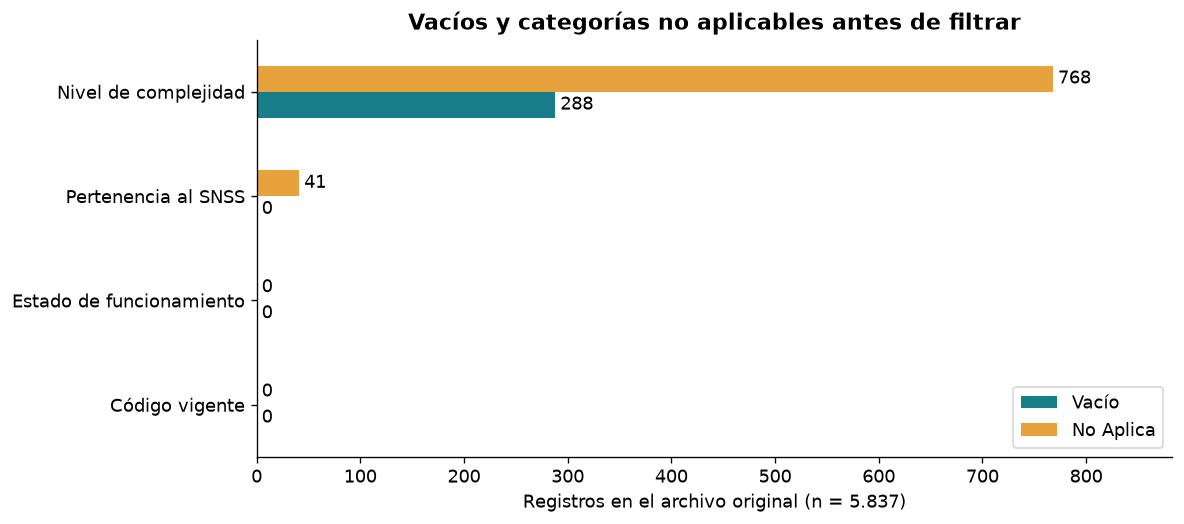

In [4]:
COLUMNAS_NECESARIAS = ["EstablecimientoCodigo", "EstadoFuncionamiento", "TipoPertenenciaEstabGlosa", "NivelComplejidadEstabGlosa"]
perfil_clave = perfil_original.set_index("variable").loc[COLUMNAS_NECESARIAS]
figura, eje = plt.subplots(figsize=(10, 4.5))
perfil_clave[["vacios", "no_aplica"]].rename(columns={"vacios": "Vacío", "no_aplica": "No Aplica"}).plot.barh(ax=eje, color=COLORES[:2])
eje.set_yticklabels(["Código vigente", "Estado de funcionamiento", "Pertenencia al SNSS", "Nivel de complejidad"])
eje.set_xlabel("Registros en el archivo original (n = 5.837)")
eje.set_ylabel("")
eje.set_title("Vacíos y categorías no aplicables antes de filtrar")
for contenedor in eje.containers:
    eje.bar_label(contenedor, padding=3)
eje.margins(x=0.15)
figura.tight_layout()
figura.savefig(DIR_FIGURAS / "01_completitud.png", bbox_inches="tight")
plt.show()

**Interpretación.** El archivo contiene **288 celdas vacías y 768 `No Aplica` en complejidad**, además de **41 `No Aplica` en pertenencia**. Estos recuentos corresponden a todo el archivo; cambiarán al restringirlo a vigentes. No se detectaron códigos ausentes ni repetidos. La principal restricción para comparar complejidad será disponer de una categoría baja, mediana o alta.

### 2.2 Frecuencias originales y coherencia de la vigencia
Contaremos las etiquetas tal como aparecen. Esto permitirá identificar variantes de mayúsculas y estados incompatibles con la población definida. Las cadenas vacías se mostrarán como `[Vacío]` solo en la tabla de presentación.

In [5]:
frecuencias_originales = []
for columna in COLUMNAS_NECESARIAS[1:]:
    frecuencia = datos_originales[columna].replace("", "[Vacío]").value_counts(dropna=False).rename_axis("categoria").reset_index(name="cantidad")
    frecuencia.insert(0, "variable", columna)
    frecuencias_originales.append(frecuencia)
    print(columna)
    display(frecuencia)
frecuencias_originales = pd.concat(frecuencias_originales, ignore_index=True)

EstadoFuncionamiento


,variable,categoria,cantidad
0,EstadoFuncionamiento,Vigente en Operación Habitual,5271
1,EstadoFuncionamiento,Cerrado,431
2,EstadoFuncionamiento,Vigente en operación habitual,135


TipoPertenenciaEstabGlosa


,variable,categoria,cantidad
0,TipoPertenenciaEstabGlosa,Perteneciente al Sistema Nacional de Servicios de Salud,3288
1,TipoPertenenciaEstabGlosa,No Perteneciente al Sistema Nacional de Servicios de Salud,2367
2,TipoPertenenciaEstabGlosa,No perteneciente al Sistema Nacional de Servicios de Salud,141
3,TipoPertenenciaEstabGlosa,No Aplica,41


NivelComplejidadEstabGlosa


,variable,categoria,cantidad
0,NivelComplejidadEstabGlosa,Baja Complejidad,3380
1,NivelComplejidadEstabGlosa,Mediana Complejidad,1270
2,NivelComplejidadEstabGlosa,No Aplica,768
3,NivelComplejidadEstabGlosa,[Vacío],288
4,NivelComplejidadEstabGlosa,Alta Complejidad,131


**Interpretación.** Hay **5.406 registros vigentes y 431 cerrados**. Las etiquetas de vigencia y no pertenencia presentan variantes de mayúsculas. Se unificarán porque expresan el mismo concepto. La categoría `Cerrado` se excluirá; no se deducirá vigencia a partir de una fecha de cierre vacía.

### 2.3 Reporte complementario
Guardaremos un reporte HTML sencillo con el perfil, las frecuencias y las definiciones de las métricas. Permitirá consultar el diagnóstico fuera de Jupyter. El reporte complementa las decisiones explicadas en este cuaderno y conserva separadas las celdas vacías de `No Aplica`.

In [6]:
reporte_html = """<!doctype html><html lang="es"><meta charset="utf-8">
<title>Grupo 1 · Perfil del registro</title>
<style>body{font:15px Arial;max-width:1400px;margin:35px auto;padding:0 25px;color:#20313d}h1,h2{color:#126773}table{border-collapse:collapse;width:100%;font-size:13px}th,td{padding:8px;border:1px solid #d6e1e5;text-align:left}th{background:#e8f3f3}tr:nth-child(even){background:#f7fafb}</style>
<h1>Grupo 1 · Perfil del registro original</h1>
<p>5.837 registros y 33 columnas. Este reporte describe la entrada, antes de filtrar.</p>
<p>Vacío: celda ausente o sin contenido tras quitar espacios. No Aplica: etiqueta explícita. Valores distintos: categorías observadas después de unificar espacios y mayúsculas, excluidos los vacíos. El tipo de almacenamiento es texto porque se preservaron los códigos.</p>
<h2>Completitud y diversidad</h2>"""
reporte_html += perfil_original.to_html(index=False)
reporte_html += "<h2>Frecuencias de las variables clave</h2>" + frecuencias_originales.to_html(index=False)
reporte_html += "<h2>Lectura del diagnóstico</h2><p>Se detectan 431 registros cerrados. La población vigente requiere un filtro explícito. Los valores No Aplica no se imputarán como categorías analíticas.</p></html>"
(RAIZ / "docs/reporte_descriptivo.html").write_text(reporte_html, encoding="utf-8")
print("Reporte descriptivo guardado en docs/reporte_descriptivo.html")

Reporte descriptivo guardado en docs/reporte_descriptivo.html


## 3. Limpieza y delimitación de la población
### 3.1 Estandarización de categorías
Trabajaremos sobre una copia. Conservaremos un número de fila de origen para rastrear cada exclusión. Reduciremos espacios y diferencias de mayúsculas y aplicaremos correspondencias explícitas.

No se cambiará `No Aplica` por `No perteneciente`. Tampoco se asignará complejidad por el tipo de establecimiento, porque eso introduciría supuestos no respaldados por la variable registrada.

In [7]:
MAPA_PERTENENCIA = {
    "perteneciente al sistema nacional de servicios de salud": "SNSS",
    "no perteneciente al sistema nacional de servicios de salud": "No SNSS"
}
MAPA_COMPLEJIDAD = {"baja complejidad": "Baja", "mediana complejidad": "Mediana", "alta complejidad": "Alta"}
ESTADOS_VIGENTES = ["vigente en operación habitual", "vigente en operación transitoria"]

datos_trabajo = datos_originales.copy()
datos_trabajo["fila_origen"] = np.arange(2, len(datos_trabajo) + 2)  # Incluye la fila de encabezado del CSV.
datos_trabajo["codigo_establecimiento"] = normalizar_texto(datos_trabajo["EstablecimientoCodigo"])
datos_trabajo["estado_normalizado"] = normalizar_texto(datos_trabajo["EstadoFuncionamiento"])
datos_trabajo["pertenencia_original_normalizada"] = normalizar_texto(datos_trabajo["TipoPertenenciaEstabGlosa"])
datos_trabajo["complejidad_original_normalizada"] = normalizar_texto(datos_trabajo["NivelComplejidadEstabGlosa"])
datos_trabajo["pertenencia_snss"] = datos_trabajo["pertenencia_original_normalizada"].map(MAPA_PERTENENCIA)
datos_trabajo["complejidad"] = datos_trabajo["complejidad_original_normalizada"].map(MAPA_COMPLEJIDAD)

correspondencias = []
for original, nueva in [("TipoPertenenciaEstabGlosa", "pertenencia_snss"), ("NivelComplejidadEstabGlosa", "complejidad")]:
    tabla = datos_trabajo.groupby([original, nueva], dropna=False).size().reset_index(name="cantidad")
    tabla.columns = ["categoria_original", "categoria_analitica", "cantidad"]
    tabla.insert(0, "variable", original)
    correspondencias.append(tabla)
correspondencias = pd.concat(correspondencias, ignore_index=True)
display(correspondencias)

,variable,categoria_original,categoria_analitica,cantidad
0,TipoPertenenciaEstabGlosa,No Aplica,NaN,41
1,TipoPertenenciaEstabGlosa,No Perteneciente al Sistema Nacional de Servicios de Salud,No SNSS,2367
2,TipoPertenenciaEstabGlosa,No perteneciente al Sistema Nacional de Servicios de Salud,No SNSS,141
3,TipoPertenenciaEstabGlosa,Perteneciente al Sistema Nacional de Servicios de Salud,SNSS,3288
4,NivelComplejidadEstabGlosa,,NaN,288
5,NivelComplejidadEstabGlosa,Alta Complejidad,Alta,131
6,NivelComplejidadEstabGlosa,Baja Complejidad,Baja,3380
7,NivelComplejidadEstabGlosa,Mediana Complejidad,Mediana,1270
8,NivelComplejidadEstabGlosa,No Aplica,NaN,768


**Interpretación.** Se unificaron las dos formas de escribir la no pertenencia. Las categorías de complejidad se redujeron a etiquetas breves conservando su significado. Los resultados sin correspondencia todavía no son imputaciones ni exclusiones: indican filas que deberán revisarse mediante reglas explícitas.

### 3.2 Reglas de inclusión y registro de exclusiones
Aplicaremos filtros en orden. Cada fila excluida tendrá un solo motivo: el primer criterio que incumpla. Por eso los recuentos por filtro son secuenciales y no deben confundirse con los recuentos iniciales de faltantes.

1. Estado vigente habitual o transitorio.
2. Código informado.
3. Repeticiones exactas: conservar una copia.
4. Si un código sigue repetido con registros diferentes, excluir sus filas y documentarlas para revisión; no elegir una versión arbitraria.
5. Pertenencia clasificable en los dos grupos del estudio.
6. Complejidad informada, aplicable y reconocida como baja, mediana o alta.

No imputaremos las variables de la pregunta. Asignar su moda aumentaría artificialmente la categoría mayoritaria y podría alterar la relación que queremos describir. Se acepta una población más restringida y se cuantifica esa pérdida.

In [8]:
def aplicar_filtro(datos, condicion, paso, motivo, bitacora, exclusiones):
    """Filtra filas y registra su primer motivo de exclusión."""
    condicion = condicion.fillna(False)
    excluidos = datos.loc[~condicion].copy()
    excluidos["paso_exclusion"] = paso
    excluidos["motivo_exclusion"] = motivo
    exclusiones.append(excluidos)
    restantes = datos.loc[condicion].copy()
    bitacora.append({"paso": paso, "regla": motivo, "antes": len(datos),
                     "excluidos": len(excluidos), "restantes": len(restantes)})
    return restantes

bitacora_filtros = []
registros_excluidos = []
poblacion = datos_trabajo.copy()
poblacion = aplicar_filtro(poblacion, poblacion["estado_normalizado"].isin(ESTADOS_VIGENTES),
                          "F01", "Conservar estado vigente", bitacora_filtros, registros_excluidos)
poblacion = aplicar_filtro(poblacion, poblacion["codigo_establecimiento"].notna() & poblacion["codigo_establecimiento"].ne(""),
                          "F02", "Código informado", bitacora_filtros, registros_excluidos)
poblacion = aplicar_filtro(poblacion, ~poblacion.duplicated(subset=list(datos_originales.columns)),
                          "F03", "Una copia de filas exactamente repetidas", bitacora_filtros, registros_excluidos)
poblacion = aplicar_filtro(poblacion, ~poblacion["codigo_establecimiento"].duplicated(keep=False),
                          "F04", "Excluir códigos con registros distintos en conflicto", bitacora_filtros, registros_excluidos)
poblacion_vigente = poblacion.copy()  # Denominador previo a exigir categorías analíticas.
poblacion = aplicar_filtro(poblacion, poblacion["pertenencia_snss"].notna(),
                          "F05", "Pertenencia clasificable: excluir No Aplica, vacíos o no reconocidos", bitacora_filtros, registros_excluidos)
poblacion = aplicar_filtro(poblacion, poblacion["complejidad_original_normalizada"].notna() & poblacion["complejidad_original_normalizada"].ne(""),
                          "F06", "Complejidad informada: excluir vacíos", bitacora_filtros, registros_excluidos)
poblacion = aplicar_filtro(poblacion, poblacion["complejidad_original_normalizada"].ne("no aplica"),
                          "F07", "Complejidad aplicable: excluir No Aplica", bitacora_filtros, registros_excluidos)
poblacion = aplicar_filtro(poblacion, poblacion["complejidad"].notna(),
                          "F08", "Complejidad reconocida: Baja, Mediana o Alta", bitacora_filtros, registros_excluidos)
tabla_filtros = pd.DataFrame(bitacora_filtros)
exclusiones = pd.concat(registros_excluidos, ignore_index=True)
display(tabla_filtros)
print("Población final:", len(poblacion))

,paso,regla,antes,excluidos,restantes
0,F01,Conservar estado vigente,5837,431,5406
1,F02,Código informado,5406,0,5406
2,F03,Una copia de filas exactamente repetidas,5406,0,5406
3,F04,Excluir códigos con registros distintos en conflicto,5406,0,5406
4,F05,"Pertenencia clasificable: excluir No Aplica, vacíos o no reconocidos",5406,41,5365
5,F06,Complejidad informada: excluir vacíos,5365,59,5306
6,F07,Complejidad aplicable: excluir No Aplica,5306,703,4603
7,F08,"Complejidad reconocida: Baja, Mediana o Alta",4603,0,4603


Población final: 4603


**Resultado e interpretación.** Se excluyeron **431 cerrados**, **41 vigentes con pertenencia `No Aplica`**, **59 con complejidad vacía** y **703 con complejidad `No Aplica`** después de los filtros previos. No se perdieron filas por códigos ausentes, duplicados o categorías inesperadas. Quedaron **4.603 establecimientos**, el **78,86 % del archivo** y el **85,15 % de los 5.406 vigentes**. Ese es el **denominador general** del análisis: 5.837 − 1.234 excluidos = 4.603.

La población final responde a la definición acordada. Los 803 vigentes excluidos por las variables del estudio no deben desaparecer de la interpretación: las conclusiones estarán condicionadas a contar con categorías utilizables.

### 3.3 Efecto de los filtros y posible selección
Representaremos los tamaños de las etapas y compararemos la proporción retenida dentro de cada grupo de pertenencia entre los vigentes con código válido. Esto permite evaluar si la disponibilidad de complejidad restringe de manera distinta a los grupos.

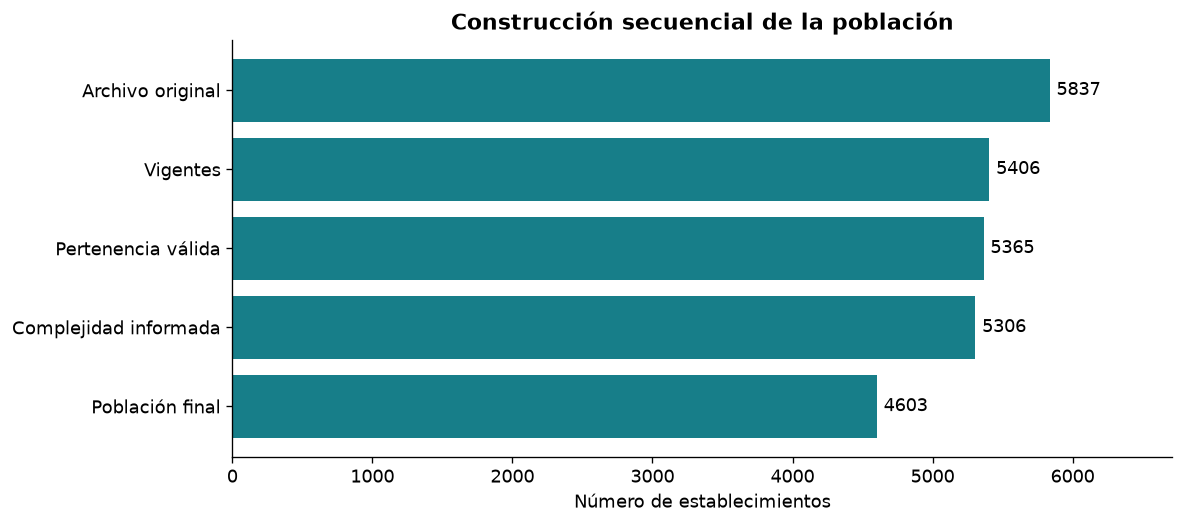

,vigentes_con_pertenencia,incluidos,excluidos_por_complejidad,porcentaje_retenido
pertenencia_snss,,,,
SNSS,3096,3065,31,99.00
No SNSS,2269,1538,731,67.78


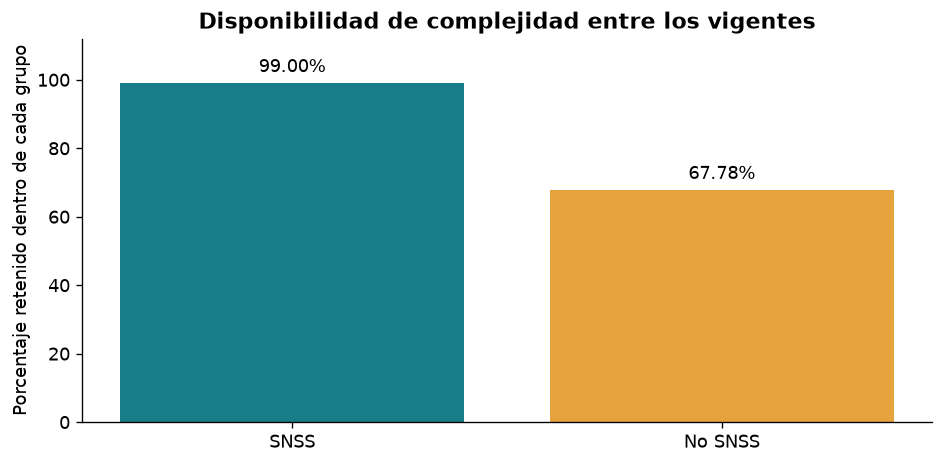

In [9]:
figura, eje = plt.subplots(figsize=(10, 4.5))
etapas = ["Archivo original", "Vigentes", "Pertenencia válida", "Complejidad informada", "Población final"]
cantidades = [len(datos_originales), len(poblacion_vigente), int(tabla_filtros.loc[4, "restantes"]), int(tabla_filtros.loc[5, "restantes"]), len(poblacion)]
barras = eje.barh(etapas[::-1], cantidades[::-1], color="#177E89")
eje.bar_label(barras, padding=4)
eje.set_xlim(0, max(cantidades) * 1.15)
eje.set_xlabel("Número de establecimientos")
eje.set_title("Construcción secuencial de la población")
figura.tight_layout()
figura.savefig(DIR_FIGURAS / "02_filtros.png", bbox_inches="tight")
plt.show()

retencion = pd.DataFrame({"vigentes_con_pertenencia": poblacion_vigente["pertenencia_snss"].value_counts(),
                         "incluidos": poblacion["pertenencia_snss"].value_counts()}).reindex(orden_grupos)
retencion["excluidos_por_complejidad"] = retencion["vigentes_con_pertenencia"] - retencion["incluidos"]
retencion["porcentaje_retenido"] = retencion["incluidos"] / retencion["vigentes_con_pertenencia"] * 100
display(retencion.round(2))
figura, eje = plt.subplots(figsize=(8, 4))
barras = eje.bar(orden_grupos, retencion["porcentaje_retenido"], color=COLORES[:2])
eje.bar_label(barras, fmt="%.2f%%", padding=4)
eje.set_ylim(0, 112)
eje.set_ylabel("Porcentaje retenido dentro de cada grupo")
eje.set_title("Disponibilidad de complejidad entre los vigentes")
figura.tight_layout()
figura.savefig(DIR_FIGURAS / "03_retencion.png", bbox_inches="tight")
plt.show()

**Interpretación.** Se retuvo a **3.065 de 3.096 establecimientos SNSS (99,00 %)** y **1.538 de 2.269 No SNSS (67,78 %)**. La disponibilidad de complejidad es desigual. No podemos suponer que los No SNSS excluidos tengan la misma distribución que los incluidos; extenderles las conclusiones podría producir una interpretación sesgada. Los 41 vigentes sin pertenencia clasificable no forman parte de estos dos denominadores.

### 3.4 Selección de variables
Aplicaremos las decisiones del diccionario de F1. Usaremos código y estado para controles, y pertenencia y complejidad para el análisis. Se conservará una tabla limpia con identificadores, mientras que la matriz numérica incluirá únicamente las categorías codificadas.

In [10]:
diccionario = pd.read_csv(RAIZ / "docs/diccionario_analitico.csv")
display(diccionario[["variable", "decision", "justificacion"]])
datos_limpios = poblacion[["fila_origen", "codigo_establecimiento", "estado_normalizado", "pertenencia_snss", "complejidad"]].reset_index(drop=True)
display(datos_limpios.head())

,variable,decision,justificacion
0,EstablecimientoCodigoAntiguo,Excluir,Código histórico; usaremos el código vigente.
1,EstablecimientoCodigo,Conservar para trazabilidad,Comprueba unicidad; no se interpreta como cantidad.
2,EstablecimientoCodigoMadreAntiguo,Excluir,La jerarquía institucional no forma parte de la pregunta.
3,EstablecimientoCodigoMadreNuevo,Excluir,La jerarquía institucional no forma parte de la pregunta.
4,RegionCodigo,Excluir,Análisis territorial fuera del alcance.
5,RegionGlosa,Excluir,Análisis territorial fuera del alcance.
6,SeremiSaludCodigo_ServicioDeSaludCodigo,Excluir,No se compararán servicios de salud o SEREMI.
7,SeremiSaludGlosa_ServicioDeSaludGlosa,Excluir,No se compararán servicios de salud o SEREMI.
8,TipoPertenenciaEstabGlosa,Conservar para análisis,Dimensión administrativa; primera variable de la pregunta.
9,TipoEstablecimientoGlosa,Excluir,"El análisis acordado compara pertenencia y complejidad, sin estratificar por tipo."


,fila_origen,codigo_establecimiento,estado_normalizado,pertenencia_snss,complejidad
0,2,101011,vigente en operación habitual,SNSS,Baja
1,3,200601,vigente en operación habitual,SNSS,Mediana
2,4,101608,vigente en operación habitual,SNSS,Mediana
3,5,101012,vigente en operación habitual,SNSS,Baja
4,6,101607,vigente en operación habitual,SNSS,Mediana


**Interpretación.** Se excluyen **29 columnas originales** por quedar fuera del alcance; las otras cuatro se usan para filtros, trazabilidad o análisis. No se imputan fechas ni coordenadas que no se utilizarán. Tampoco se buscan atípicos con diagramas de caja sobre códigos: los identificadores no representan magnitudes. Las dos variables analíticas son categorías, por lo que su control se basa en etiquetas válidas y frecuencias.

## 4. Descripción de la población y transformación
### 4.1 Distribuciones individuales
Contaremos establecimientos por pertenencia y complejidad. Los gráficos mostrarán cantidades y porcentajes de la población final, sin ponderar por camas, personal ni atenciones.

Denominador general: 4603


,cantidad,porcentaje
pertenencia_snss,,
SNSS,3065,66.59
No SNSS,1538,33.41


,cantidad,porcentaje
complejidad,,
Baja,3270,71.04
Mediana,1206,26.20
Alta,127,2.76


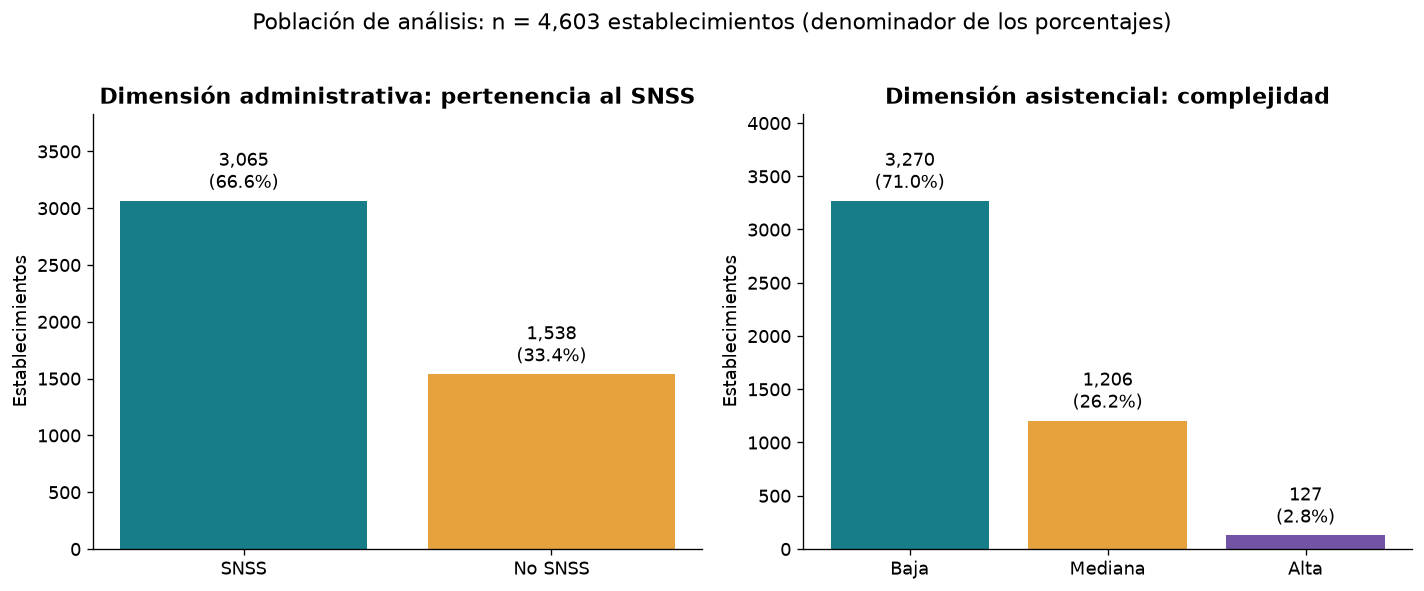

In [11]:
def resumir_categorias(serie, orden):
    """Devuelve frecuencias y porcentajes con un orden declarado."""
    conteos = serie.value_counts().reindex(orden, fill_value=0)
    return pd.DataFrame({"cantidad": conteos, "porcentaje": conteos / len(serie) * 100})

DENOMINADOR = len(datos_limpios)
assert DENOMINADOR == int(tabla_filtros["restantes"].iloc[-1])
print("Denominador general:", DENOMINADOR)
resumen_pertenencia = resumir_categorias(datos_limpios["pertenencia_snss"], orden_grupos)
resumen_complejidad = resumir_categorias(datos_limpios["complejidad"], orden_complejidad)
display(resumen_pertenencia.round(2))
display(resumen_complejidad.round(2))
figura, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, resumen, titulo in zip(ejes, [resumen_pertenencia, resumen_complejidad], ["Dimensión administrativa: pertenencia al SNSS", "Dimensión asistencial: complejidad"]):
    barras = eje.bar(resumen.index, resumen["cantidad"], color=COLORES[:len(resumen)])
    etiquetas = [f"{int(fila.cantidad):,}\n({fila.porcentaje:.1f}%)" for fila in resumen.itertuples()]
    eje.bar_label(barras, labels=etiquetas, padding=4)
    eje.set_ylim(0, resumen["cantidad"].max() * 1.25)
    eje.set_title(titulo)
    eje.set_ylabel("Establecimientos")
figura.suptitle(f"Población de análisis: n = {DENOMINADOR:,} establecimientos (denominador de los porcentajes)", y=1.02)
figura.tight_layout()
figura.savefig(DIR_FIGURAS / "04_distribuciones.png", bbox_inches="tight")
plt.show()

**Interpretación.** Sobre el denominador general (**n = 4.603**), la población incluye **3.065 establecimientos SNSS** y **1.538 No SNSS**. Predomina la complejidad baja (**3.270**), seguida de la mediana (**1.206**) y la alta (**127**). Estos totales no muestran todavía cómo se reparte la complejidad dentro de cada grupo; además, el distinto tamaño de los grupos obliga a comparar porcentajes internos.

### 4.2 Tabla de contingencia y porcentajes por grupo
Construiremos una tabla de dos filas por tres columnas. Las frecuencias responden cuántos establecimientos hay en cada combinación; los porcentajes por fila responden cómo se distribuye la complejidad dentro de cada pertenencia. Cada fila porcentual debe sumar 100 %. Los denominadores son el total de cada grupo: SNSS y No SNSS. El porcentaje por columna se muestra solo como apoyo.

In [12]:
tabla_contingencia = pd.crosstab(datos_limpios["pertenencia_snss"], datos_limpios["complejidad"])
tabla_contingencia = tabla_contingencia.reindex(index=orden_grupos, columns=orden_complejidad, fill_value=0)
porcentajes_grupo = tabla_contingencia.div(tabla_contingencia.sum(axis=1), axis=0) * 100
denominadores_grupo = tabla_contingencia.sum(axis=1).rename("denominador")
porcentajes_columna = tabla_contingencia.div(tabla_contingencia.sum(axis=0), axis=1) * 100
display(tabla_contingencia)
display(denominadores_grupo.to_frame())
display(porcentajes_grupo.round(2))
print("Apoyo: porcentaje por columna (dentro de cada nivel de complejidad)")
display(porcentajes_columna.round(2))
assert denominadores_grupo.sum() == DENOMINADOR
assert tabla_contingencia.to_numpy().sum() == len(datos_limpios)
assert np.allclose(porcentajes_grupo.sum(axis=1), 100)

complejidad,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,2810,183,72
No SNSS,460,1023,55


,denominador
pertenencia_snss,
SNSS,3065
No SNSS,1538


complejidad,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,91.68,5.97,2.35
No SNSS,29.91,66.51,3.58


Apoyo: porcentaje por columna (dentro de cada nivel de complejidad)


complejidad,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,85.93,15.17,56.69
No SNSS,14.07,84.83,43.31


**Interpretación.** Entre los establecimientos SNSS (**n = 3.065**), la complejidad baja representa **91,68 %**, la mediana **5,97 %** y la alta **2,35 %**. Entre los No SNSS (**n = 1.538**), las proporciones son **29,91 %**, **66,51 %** y **3,58 %**, respectivamente. Se lee "de los establecimientos SNSS, qué proporción es de cada nivel", que es lo que responde la pregunta. La diferencia descriptiva más marcada aparece entre baja y mediana complejidad.

En alta complejidad hay **72 SNSS** frente a **55 No SNSS**, aunque la proporción interna es mayor en el segundo grupo. Cantidades y porcentajes responden preguntas distintas; no deben intercambiarse.

### 4.3 Comparación visual entre los grupos
Usaremos barras al 100 % y un mapa de calor de porcentajes, anotando también las frecuencias. El orden baja–mediana–alta facilitará la lectura sin asignar distancias numéricas entre niveles.

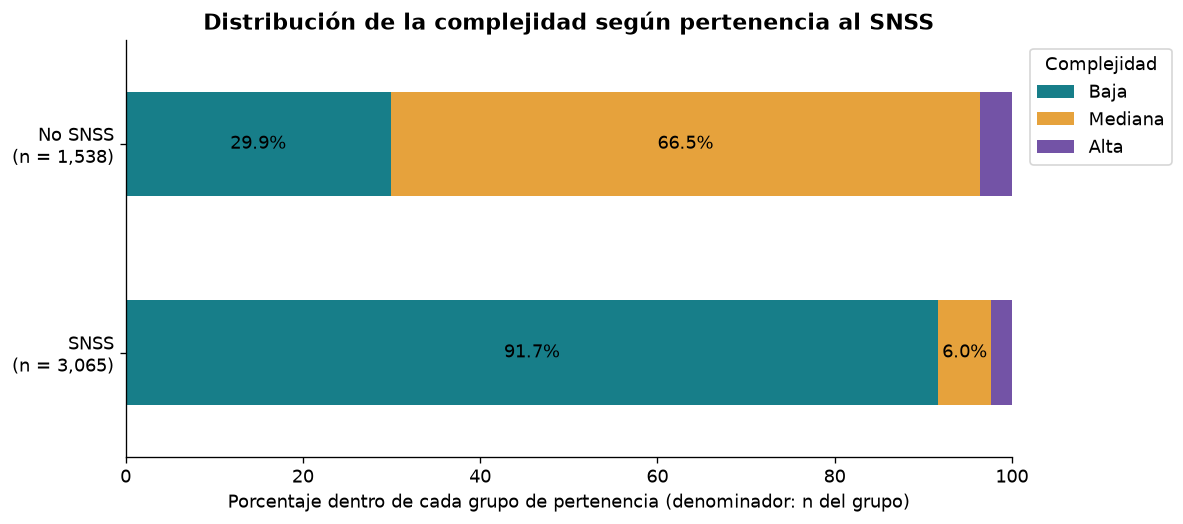

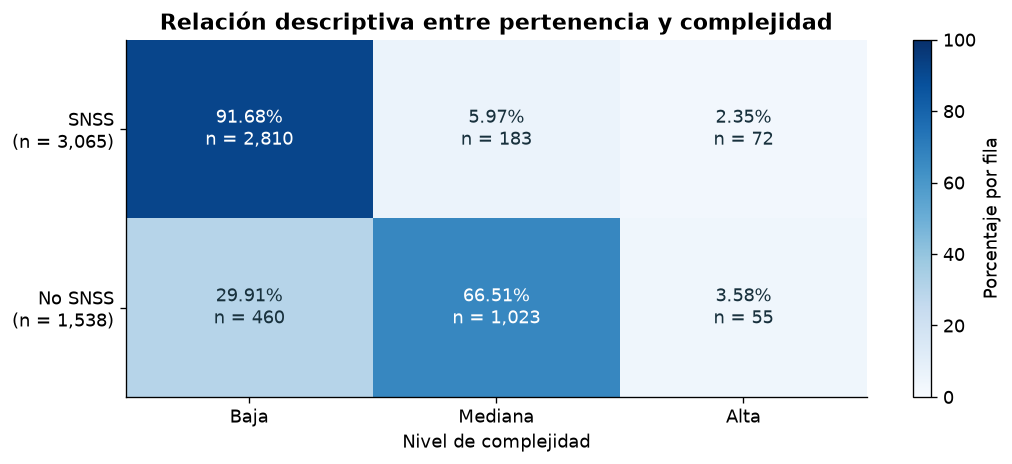

In [13]:
figura, eje = plt.subplots(figsize=(10, 4.5))
porcentajes_grupo.plot.barh(stacked=True, color=COLORES, ax=eje)
for fila, grupo in enumerate(orden_grupos):
    inicio = 0
    for nivel in orden_complejidad:
        porcentaje = porcentajes_grupo.loc[grupo, nivel]
        if porcentaje >= 5:
            eje.text(inicio + porcentaje / 2, fila, f"{porcentaje:.1f}%", ha="center", va="center", fontsize=11)
        inicio += porcentaje
etiquetas_grupo = [f"{grupo}\n(n = {denominadores_grupo[grupo]:,})" for grupo in orden_grupos]
eje.set_yticks(range(2), etiquetas_grupo)
eje.set_xlim(0, 100)
eje.set_xlabel("Porcentaje dentro de cada grupo de pertenencia (denominador: n del grupo)")
eje.set_ylabel("")
eje.set_title("Distribución de la complejidad según pertenencia al SNSS")
eje.legend(title="Complejidad", bbox_to_anchor=(1.01, 1), loc="upper left")
figura.tight_layout()
figura.savefig(DIR_FIGURAS / "05_composicion.png", bbox_inches="tight")
plt.show()

figura, eje = plt.subplots(figsize=(9, 4))
imagen = eje.imshow(porcentajes_grupo, cmap="Blues", vmin=0, vmax=100, aspect="auto")
eje.set_xticks(range(3), orden_complejidad)
eje.set_yticks(range(2), etiquetas_grupo)
for fila in range(2):
    for columna in range(3):
        porcentaje = porcentajes_grupo.iloc[fila, columna]
        cantidad = tabla_contingencia.iloc[fila, columna]
        eje.text(columna, fila, f"{porcentaje:.2f}%\nn = {cantidad:,}", ha="center", va="center", color="white" if porcentaje > 55 else "#18313d")
eje.set_title("Relación descriptiva entre pertenencia y complejidad")
eje.set_xlabel("Nivel de complejidad")
figura.colorbar(imagen, ax=eje, label="Porcentaje por fila")
figura.tight_layout()
figura.savefig(DIR_FIGURAS / "06_mapa_contingencia.png", bbox_inches="tight")
plt.show()

**Interpretación.** Las barras y el mapa muestran distribuciones distintas en la población seleccionada: predomina la complejidad baja en los SNSS y la mediana en los No SNSS. Esta evidencia describe la relación observada, pero todavía no cuantifica su magnitud mediante una medida de asociación ni evalúa independencia.

**Por qué no se incluye una correlación de Pearson.** Asignar números arbitrarios a estas categorías impondría una escala que la pregunta no define. El mapa representa frecuencias y porcentajes, no coeficientes de correlación. En F4 se propondrá una prueba de independencia y V de Cramér, revisando sus condiciones, el alcance inferencial del registro y el papel del tipo de establecimiento.

> **Cambio por devolución docente (prioridad 4).** Antes decía “En F3–F4 se propondrá…”. Se traslada a F4 y se agrega el tipo de establecimiento.

### 4.4 Codificación numérica
Aplicaremos One-Hot con `pd.get_dummies`: cada categoría se transforma en una columna 0/1 con nombre en español. Es una operación sencilla que evita asignar distancias entre los niveles de complejidad. Su orden conceptual se conserva en tablas y gráficos.

Mantendremos las cinco columnas binarias para facilitar la lectura: dos de pertenencia y tres de complejidad. Cada grupo debe sumar uno por establecimiento. Si posteriormente se utilizara una regresión con intercepto, habría que definir categorías de referencia; esa tarea no corresponde a este análisis de contingencia.

In [14]:
COLUMNAS_NUMERICAS = ["snss_perteneciente", "snss_no_perteneciente", "complejidad_baja", "complejidad_mediana", "complejidad_alta"]

def codificar_variables(datos):
    """Codifica las dos variables después de comprobar sus categorías."""
    necesarias = ["pertenencia_snss", "complejidad"]
    if not set(necesarias).issubset(datos.columns):
        raise KeyError("Faltan columnas de pertenencia o complejidad.")
    if datos[necesarias].isna().any().any():
        raise ValueError("Las variables analíticas contienen faltantes.")
    if not datos["pertenencia_snss"].isin(orden_grupos).all() or not datos["complejidad"].isin(orden_complejidad).all():
        raise ValueError("Se encontraron categorías no reconocidas.")
    numericos = pd.get_dummies(datos[necesarias], prefix=["snss", "complejidad"], dtype=int)
    numericos = numericos.rename(columns={"snss_SNSS": "snss_perteneciente", "snss_No SNSS": "snss_no_perteneciente",
                                          "complejidad_Baja": "complejidad_baja", "complejidad_Mediana": "complejidad_mediana", "complejidad_Alta": "complejidad_alta"})
    return numericos.reindex(columns=COLUMNAS_NUMERICAS, fill_value=0)

datos_numericos = codificar_variables(datos_limpios)
display(pd.concat([datos_limpios[["pertenencia_snss", "complejidad"]].head(6), datos_numericos.head(6)], axis=1))
print("Dimensiones de la matriz:", datos_numericos.shape)

,pertenencia_snss,complejidad,snss_perteneciente,snss_no_perteneciente,complejidad_baja,complejidad_mediana,complejidad_alta
0,SNSS,Baja,1,0,1,0,0
1,SNSS,Mediana,1,0,0,1,0
2,SNSS,Mediana,1,0,0,1,0
3,SNSS,Baja,1,0,1,0,0
4,SNSS,Mediana,1,0,0,1,0
5,SNSS,Baja,1,0,1,0,0


Dimensiones de la matriz: (4603, 5)


**Interpretación.** Las dos variables producen **cinco columnas numéricas para 4.603 establecimientos**. Cada uno activa una columna de pertenencia y una de complejidad. La cantidad de filas se conserva. Los códigos y las etiquetas legibles permanecen en archivos separados para verificar la correspondencia sin tratarlos como medidas.

## 5. Revisión del escalamiento
La selección final no contiene variables continuas: todas las columnas son indicadores 0/1. Comprobaremos sus rangos y conservaremos esa escala.

| Alternativa | Decisión y motivo |
|---|---|
| StandardScaler | No se aplica: convertiría indicadores en valores centrados dependientes de su frecuencia, sin aportar a una tabla de contingencia. |
| MinMaxScaler | No se aplica: las columnas ya contienen 0 y 1; no cambiaría sus valores. |
| RobustScaler | No se aplica: no hay medidas continuas ni atípicos numéricos que requieran este tratamiento. |

La matriz quedará numérica y acotada en [0, 1]. Esto no equivale a afirmar que tiene media 0 y desviación estándar 1. No se incorporarán coordenadas o antigüedad únicamente para aplicar un escalador.

In [15]:
control_escala = pd.DataFrame({"minimo": datos_numericos.min(), "maximo": datos_numericos.max(),
                              "media_proporcion": datos_numericos.mean(), "tipo": datos_numericos.dtypes.astype(str)})
display(control_escala)
assert datos_numericos.isin([0, 1]).all().all()

,minimo,maximo,media_proporcion,tipo
snss_perteneciente,0,1,0.665870,int64
snss_no_perteneciente,0,1,0.334130,int64
complejidad_baja,0,1,0.710406,int64
complejidad_mediana,0,1,0.262003,int64
complejidad_alta,0,1,0.027591,int64


**Interpretación.** Las cinco columnas tienen valores 0/1. Su media representa la proporción de establecimientos de cada categoría en la población final. Las diferencias entre esas medias son información descriptiva, no un defecto de escala. Por eso se conserva la codificación sin estandarizarla.

## 6. Validación técnica y pruebas de las funciones
Comprobaremos que los filtros, las etiquetas y la matriz sean coherentes. En esta etapa dos establecimientos pueden tener la misma fila binaria: pertenecen a la misma combinación de categorías. Eso no los convierte en duplicados del registro y no justifica eliminarlos.

In [16]:
def validar_resultado(limpios, numericos, filtros, excluidos):
    """Valida población, codificación, trazabilidad y conservación del origen."""
    assert limpios["codigo_establecimiento"].is_unique
    assert limpios["estado_normalizado"].isin(ESTADOS_VIGENTES).all()
    assert limpios["pertenencia_snss"].isin(orden_grupos).all()
    assert limpios["complejidad"].isin(orden_complejidad).all()
    assert not limpios.isna().any().any()
    assert numericos.select_dtypes(include="number").shape[1] == numericos.shape[1]
    assert not numericos.isna().any().any()
    assert np.isfinite(numericos.to_numpy()).all()
    assert numericos.isin([0, 1]).all().all()
    assert numericos[["snss_perteneciente", "snss_no_perteneciente"]].sum(axis=1).eq(1).all()
    assert numericos[["complejidad_baja", "complejidad_mediana", "complejidad_alta"]].sum(axis=1).eq(1).all()
    assert len(numericos) == len(limpios)
    assert len(datos_originales) == len(limpios) + len(excluidos)
    assert filtros["excluidos"].sum() == len(excluidos)
    assert excluidos["fila_origen"].is_unique
    assert set(limpios["fila_origen"]).isdisjoint(set(excluidos["fila_origen"]))
    assert set(limpios["fila_origen"]) | set(excluidos["fila_origen"]) == set(datos_trabajo["fila_origen"])
    assert hashlib.sha256(ARCHIVO.read_bytes()).hexdigest() == METADATOS_F1["sha256"]
    return "Validación completa: correcta"

print(validar_resultado(datos_limpios, datos_numericos, tabla_filtros, exclusiones))
print("Filas binarias repetidas (se conservan):", datos_numericos.duplicated().sum())
print("Combinaciones observadas:", len(datos_numericos.drop_duplicates()))

Validación completa: correcta
Filas binarias repetidas (se conservan): 4597
Combinaciones observadas: 6


**Interpretación.** La matriz tiene **seis combinaciones observadas**. Sus **4.597 filas repetidas después de codificar** representan establecimientos distintos que comparten categorías. Se conservan porque la unicidad se evaluó mediante el código, no mediante las características analíticas. Las exclusiones y las filas retenidas reconcilian exactamente con las 5.837 filas de entrada.

### 6.1 Casos normales, límite y excepciones
Usaremos ejemplos pequeños para comprobar que la codificación mantiene cinco columnas incluso si una categoría no aparece, admite una tabla vacía con esquema válido y rechaza faltantes o categorías desconocidas. También verificaremos el registro de una exclusión.

In [17]:
ejemplo = pd.DataFrame({"pertenencia_snss": ["SNSS", "No SNSS"], "complejidad": ["Baja", "Alta"]})
codificado = codificar_variables(ejemplo)
assert codificado.shape == (2, 5)
assert codificado["complejidad_mediana"].sum() == 0
assert codificar_variables(ejemplo.iloc[0:0]).shape == (0, 5)

def comprobar_error(datos, tipo_error):
    """Exige que una entrada inválida produzca la excepción esperada."""
    try:
        codificar_variables(datos)
    except tipo_error:
        return True
    raise AssertionError("La entrada inválida no produjo el error esperado.")

assert comprobar_error(ejemplo.drop(columns="complejidad"), KeyError)
assert comprobar_error(ejemplo.assign(complejidad="Desconocida"), ValueError)
assert comprobar_error(ejemplo.assign(complejidad=None), ValueError)
bitacora_prueba, exclusiones_prueba = [], []
retenidos_prueba = aplicar_filtro(ejemplo, pd.Series([True, False]), "PRUEBA", "Ejemplo", bitacora_prueba, exclusiones_prueba)
assert len(retenidos_prueba) == 1 and bitacora_prueba[0]["excluidos"] == 1
print("Pruebas correctas: caso normal, categorías ausentes, tabla vacía, excepciones y filtro.")

Pruebas correctas: caso normal, categorías ausentes, tabla vacía, excepciones y filtro.


## 7. Exportación y trazabilidad
Guardaremos las salidas con propósitos distintos: la población legible permite interpretar categorías; la matriz binaria permite trabajar numéricamente; la clave de filas permite relacionarlas. La tabla de contingencia será el insumo directo del análisis de asociación.

También guardaremos exclusiones, correspondencias y decisiones. Cada establecimiento aparecerá una sola vez en la población final; las filas conservarán el mismo orden en los tres archivos relacionados.

In [18]:
DIR_PROCESADO = RAIZ / "data/processed"
DIR_PROCESADO.mkdir(parents=True, exist_ok=True)
datos_limpios.to_csv(DIR_PROCESADO / "poblacion_analisis.csv", index=False, encoding="utf-8-sig")
datos_numericos.to_csv(DIR_PROCESADO / "matriz_numerica_0_1.csv", index=False, encoding="utf-8-sig")
clave_filas = datos_limpios[["fila_origen", "codigo_establecimiento"]].copy()
clave_filas.insert(0, "fila_matriz", np.arange(1, len(clave_filas) + 1))
clave_filas.to_csv(DIR_PROCESADO / "clave_filas.csv", index=False, encoding="utf-8-sig")
tabla_contingencia.to_csv(DIR_PROCESADO / "tabla_contingencia.csv", encoding="utf-8-sig")
porcentajes_grupo.to_csv(DIR_PROCESADO / "porcentajes_por_grupo.csv", encoding="utf-8-sig")
tabla_filtros.to_csv(RAIZ / "docs/tabla_filtros.csv", index=False, encoding="utf-8-sig")
columnas_auditoria = ["fila_origen", "codigo_establecimiento", "EstadoFuncionamiento", "TipoPertenenciaEstabGlosa", "NivelComplejidadEstabGlosa", "paso_exclusion", "motivo_exclusion"]
exclusiones[columnas_auditoria].to_csv(RAIZ / "docs/registros_excluidos.csv", index=False, encoding="utf-8-sig")
correspondencias.to_csv(RAIZ / "docs/correspondencias_categorias.csv", index=False, encoding="utf-8-sig")
perfil_original.to_csv(RAIZ / "docs/perfil_original.csv", index=False, encoding="utf-8-sig")
retencion.to_csv(RAIZ / "docs/retencion_por_grupo.csv", encoding="utf-8-sig")
control_escala.to_csv(RAIZ / "docs/control_escala.csv", encoding="utf-8-sig")
diccionario.to_csv(RAIZ / "docs/decisiones_variables.csv", index=False, encoding="utf-8-sig")
resumen_final = {"filas_originales": len(datos_originales), "vigentes": len(poblacion_vigente),
                 "filas_finales": len(datos_limpios), "filas_excluidas": len(exclusiones),
                 "columnas_numericas": list(datos_numericos.columns), "escala": "Indicadores binarios 0/1; no se aplicó un escalador",
                 # CAMBIO (devolución docente, prioridad 4): la prueba de independencia pasa a F4.
                 # ANTES: "prueba_asociacion": "Proyectada F3–F4",
                 "imputacion": "No aplicada a las variables analíticas", "prueba_asociacion": "Proyectada F4",
                 "dimensiones": PROYECTO["dimensiones"], "denominador": DENOMINADOR,
                 "denominadores_por_grupo": {grupo: int(n) for grupo, n in denominadores_grupo.items()},
                 "porcentajes": PROYECTO["denominador"]["porcentajes"], "sha256_original": METADATOS_F1["sha256"]}
(RAIZ / "docs/metadatos_f2.json").write_text(json.dumps(resumen_final, ensure_ascii=False, indent=2), encoding="utf-8")
# Verificación de las salidas al leerlas de nuevo.
matriz_guardada = pd.read_csv(DIR_PROCESADO / "matriz_numerica_0_1.csv")
assert matriz_guardada.equals(datos_numericos)
print("Archivos guardados y matriz exportada verificada:", matriz_guardada.shape)

Archivos guardados y matriz exportada verificada: (4603, 5)


## 8. Conclusiones y reflexión técnica

**Definición de la población.** El archivo original contenía 5.837 filas, incluidas 431 cerradas. Las reglas explícitas dejaron 4.603 establecimientos vigentes con código único y las dos categorías analíticas válidas; ese es el denominador general. La tabla de filtros y los registros excluidos permiten reconstruir la selección.

**Estandarización.** Se unificaron espacios y mayúsculas sin reemplazar el significado de las etiquetas. Los vacíos y `No Aplica` se distinguieron y no se imputaron. La codificación produjo cinco indicadores binarios sin perder establecimientos ni introducir un orden numérico artificial.

**Distribución.** En el cruce de la dimensión administrativa con la asistencial, la complejidad baja representa 91,68 % entre los SNSS (n = 3.065) y 29,91 % entre los No SNSS (n = 1.538). La mediana representa 5,97 % y 66,51 %, respectivamente. La alta representa 2,35 % y 3,58 %. La distribución observada difiere entre los grupos de la población seleccionada.

**Limitación principal.** La retención fue 99,00 % entre los SNSS y 67,78 % entre los No SNSS con pertenencia informada. Por eso no interpretamos la distribución final como si representara a todos los establecimientos vigentes, ni como una medida de capacidad asistencial.

**Qué entendimos.** La limpieza debe responder a la pregunta: conservar identificadores para controles, distinguir categorías no aplicables de vacíos y evitar imputar las variables cuya relación se investiga. Una matriz de características repetidas puede ser correcta cuando cada fila corresponde a una unidad distinta. El escalamiento solo se aplica si aporta al tipo de datos y al análisis.

**Continuidad con F3 y F4.** F3 reorganizará este flujo en clases y módulos, comprobando que reproduce exactamente estos resultados, y medirá su eficiencia. La tabla 2 × 3 queda preparada para que F4 evalúe independencia y magnitud de asociación. Antes de concluir se examinará la relación por tipo de establecimiento, porque la composición por tipo puede explicar buena parte de la diferencia observada. En esta fase no se informa un valor p ni se afirma causalidad.

> **Cambio por devolución docente (prioridad 4).** Antes, este párrafo se titulaba “Continuidad con F3–F4” y asignaba la prueba a ambas fases. Ahora F3 corresponde al diseño modular y F4 a la prueba, con la advertencia sobre el tipo de establecimiento.

### Verificación de entrega
- Cuadernos ejecutados en orden, con resultados y gráficos visibles.
- Código con nombres en español, comentarios y funciones breves.
- Fuente conservada y comprobada mediante huella.
- Decisiones, exclusiones y categorías documentadas.
- Matriz numérica, tabla legible, clave de filas y contingencia exportadas.
- Fecha de descarga, corte administrativo, mapa previo e historial real de Git pendientes de respaldo documental por el grupo.